<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 5 — Linear Models and Regularization

**Reference:** John Sukup, *scikit-learn Cookbook*, Third Edition, Chapter 5.

## Learning objectives

Notebook ini mengeksplorasi cara membangun model regresi, membandingkan regularisasi Ridge, Lasso, dan ElasticNet, serta memperluas regresi linier untuk hubungan nonlinier menggunakan fitur polinomial dan spline.

Pada setiap eksperimen, data dibagi menjadi data latih dan data uji. Evaluasi akhir menggunakan data uji yang tidak dipakai untuk melatih model. Contoh dibuat secara sintetis agar notebook bisa dijalankan tanpa mengunduh dataset eksternal.

## 1. Konsep dasar model linear

Model linear memperkirakan target dari kombinasi berbobot fitur:

\[
\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \cdots + \beta_p x_p
\]

- \(\hat{y}\): nilai target yang diprediksi.
- \(\beta_0\): intercept atau nilai dasar model.
- \(\beta_j\): koefisien yang mengatur kontribusi fitur ke-\(j\).
- \(x_j\): nilai fitur.

Ordinary Least Squares (OLS), yang digunakan oleh `LinearRegression`, mencari koefisien yang meminimalkan jumlah kuadrat residual. Model linear mudah dijadikan baseline, tetapi koefisien dapat menjadi tidak stabil ketika fitur sangat berkorelasi.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_squared_error, r2_score

RANDOM_STATE = 2026
rng = np.random.default_rng(RANDOM_STATE)
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 2. Membuat data regresi dengan fitur yang saling berkorelasi

Kumpulan data ini memiliki fitur yang informatif, beberapa fitur tiruan yang berkorelasi dengan fitur lain, dan beberapa fitur noise. Situasi seperti ini dapat membuat koefisien OLS sensitif terhadap perubahan data, sehingga cocok untuk melihat peran regularisasi.

`make_regression` membuat target awal. Setelah itu kita menambahkan kolom berkorelasi dan kolom noise dengan seed tetap agar hasil bisa direproduksi.

In [2]:
X_core, y = make_regression(
    n_samples=700,
    n_features=12,
    n_informative=7,
    noise=18.0,
    random_state=RANDOM_STATE,
)

# Tambahkan fitur duplikat yang sedikit diberi noise dan beberapa fitur noise.
X_correlated = np.column_stack([
    X_core[:, 0] + rng.normal(0, 0.08, size=len(X_core)),
    X_core[:, 3] + rng.normal(0, 0.08, size=len(X_core)),
])
X_noise = rng.normal(size=(len(X_core), 4))
X = np.column_stack([X_core, X_correlated, X_noise])
feature_names = [f"feature_{i:02d}" for i in range(X.shape[1])]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE
)

display(pd.DataFrame(X_train, columns=feature_names).head())
print(f"Jumlah sampel: {len(X)}")
print(f"Jumlah fitur: {X.shape[1]}")
print(f"Sampel latih: {len(X_train)} | sampel uji: {len(X_test)}")

,feature_00,feature_01,feature_02,feature_03,feature_04,feature_05,feature_06,feature_07,feature_08,feature_09,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,feature_16,feature_17
0,-0.017505,0.948677,-0.534909,0.098576,-0.129573,1.185917,1.058105,0.008167,-1.013211,-1.395503,-0.437984,-0.160506,-0.106307,0.095053,0.266632,0.474518,0.721965,2.020739
1,0.504743,-1.965506,-0.155018,-0.434625,-1.444574,0.474294,-0.964174,-0.192473,0.761938,1.475716,0.545997,1.090330,0.556994,-0.479618,0.165901,-0.577761,0.853612,1.374850
2,-1.808107,-0.559420,0.060377,0.778107,-1.131972,-1.190403,0.310271,0.197608,0.205333,-0.034603,-0.065066,-0.844920,-1.768954,0.763772,-0.220900,1.401948,-0.450943,-0.676200
3,-0.641101,0.734892,0.690257,1.169175,-0.929748,-2.634116,-0.577758,1.072816,2.563523,-1.058730,2.147797,0.295183,-0.657317,1.172626,1.146901,-0.843469,0.225757,0.370878
4,1.553070,-0.404904,1.660752,-0.159355,-1.087644,-0.219461,1.391295,0.242224,1.052610,0.345519,-0.286949,-1.659701,1.373140,-0.169468,1.582974,1.706842,1.791583,-1.256696


Jumlah sampel: 700
Jumlah fitur: 18
Sampel latih: 525 | sampel uji: 175


Korelasi feature_00 dengan feature_12: 0.997
Korelasi feature_03 dengan feature_13: 0.997


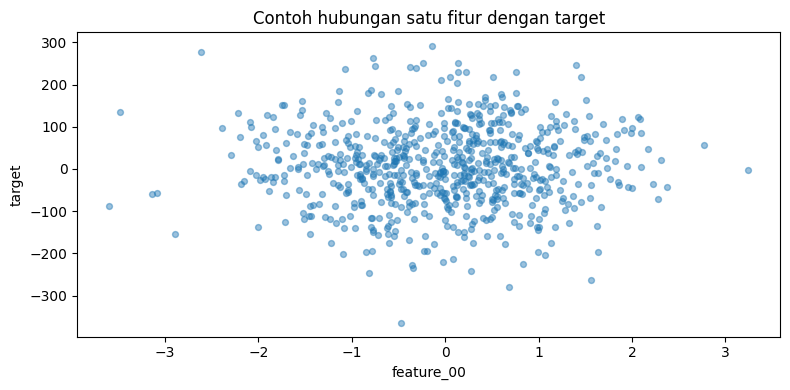

In [3]:
corr = pd.DataFrame(X, columns=feature_names).corr()
print("Korelasi feature_00 dengan feature_12:", round(corr.loc["feature_00", "feature_12"], 3))
print("Korelasi feature_03 dengan feature_13:", round(corr.loc["feature_03", "feature_13"], 3))

plt.figure(figsize=(8, 4))
plt.scatter(X[:, 0], y, alpha=0.45, s=18)
plt.xlabel("feature_00")
plt.ylabel("target")
plt.title("Contoh hubungan satu fitur dengan target")
plt.tight_layout()
plt.show()

## 3. Baseline: Ordinary Least Squares

Kita mulai dengan `LinearRegression`. Nilai **MSE** mengukur rata-rata kuadrat selisih prediksi dan nilai aktual; lebih kecil biasanya lebih baik. **R²** menunjukkan seberapa besar variasi target yang dijelaskan model pada data evaluasi. R² dapat bernilai negatif jika model lebih buruk daripada prediksi baseline berupa rata-rata target.

In [4]:
ols = make_pipeline(StandardScaler(), LinearRegression())
ols.fit(X_train, y_train)
y_pred_ols = ols.predict(X_test)

ols_mse = mean_squared_error(y_test, y_pred_ols)
ols_rmse = np.sqrt(ols_mse)
ols_r2 = r2_score(y_test, y_pred_ols)

print(f"OLS test MSE : {ols_mse:.2f}")
print(f"OLS test RMSE: {ols_rmse:.2f}")
print(f"OLS test R²  : {ols_r2:.4f}")

OLS test MSE : 307.11
OLS test RMSE: 17.52
OLS test R²  : 0.9612


## 4. Ridge dan Lasso

Regularisasi menambahkan penalti pada koefisien untuk membatasi besarnya koefisien model.

- **Ridge (L2)** memberi penalti berdasarkan kuadrat koefisien. Koefisien cenderung mengecil, tetapi umumnya tidak menjadi tepat nol.
- **Lasso (L1)** memberi penalti berdasarkan nilai absolut koefisien. Sebagian koefisien dapat menjadi nol, sehingga Lasso juga dapat berperan sebagai seleksi fitur.
- Parameter `alpha` mengontrol kekuatan penalti. `alpha` yang terlalu besar dapat menyederhanakan model secara berlebihan.

Fitur distandardisasi di dalam pipeline supaya perbedaan skala tidak mendominasi penalti.

In [5]:
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
lasso = make_pipeline(StandardScaler(), Lasso(alpha=1.0, max_iter=20000))

models = {
    "OLS": ols,
    "Ridge": ridge,
    "Lasso": lasso,
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    regressor = model.named_steps[list(model.named_steps)[-1]]
    coefs = regressor.coef_
    rows.append({
        "Model": name,
        "Test MSE": mean_squared_error(y_test, pred),
        "Test R²": r2_score(y_test, pred),
        "Jumlah koefisien non-zero": int(np.count_nonzero(np.abs(coefs) > 1e-8)),
        "Norma koefisien L2": float(np.linalg.norm(coefs)),
    })

model_comparison = pd.DataFrame(rows).sort_values("Test MSE").reset_index(drop=True)
display(model_comparison.round(4))

,Model,Test MSE,Test R²,Jumlah koefisien non-zero,Norma koefisien L2
0,OLS,307.1145,0.9612,18,101.8165
1,Lasso,315.7122,0.9601,7,94.7753
2,Ridge,329.8543,0.9583,18,81.7008


### Mengamati koefisien

Grafik di bawah menunjukkan 18 koefisien pertama dari model. Fokus utama bukan mencari model dengan koefisien paling kecil, tetapi melihat bagaimana penalti mengubah koefisien sambil mempertahankan performa pada data uji.

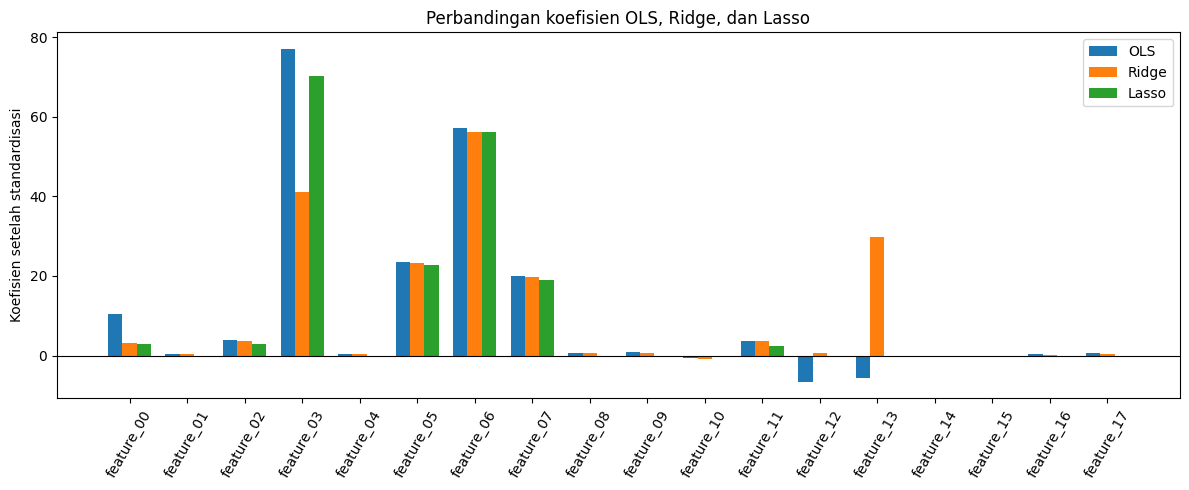

In [6]:
coef_models = {
    "OLS": ols.named_steps["linearregression"].coef_,
    "Ridge": ridge.named_steps["ridge"].coef_,
    "Lasso": lasso.named_steps["lasso"].coef_,
}
show_n = 18
x_pos = np.arange(show_n)
width = 0.25

plt.figure(figsize=(12, 5))
for idx, (name, coef) in enumerate(coef_models.items()):
    plt.bar(x_pos + (idx - 1) * width, coef[:show_n], width=width, label=name)
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(x_pos, feature_names[:show_n], rotation=60)
plt.ylabel("Koefisien setelah standardisasi")
plt.title("Perbandingan koefisien OLS, Ridge, dan Lasso")
plt.legend()
plt.tight_layout()
plt.show()

## 5. ElasticNet

ElasticNet menggabungkan penalti L1 dan L2. Parameter `l1_ratio` mengatur campuran: nilai mendekati 1 lebih mirip Lasso, sedangkan nilai mendekati 0 lebih mirip Ridge. Pendekatan gabungan berguna ketika terdapat fitur yang saling berkorelasi dan kita ingin mengendalikan ukuran koefisien sekaligus memungkinkan sebagian koefisien menjadi nol.

In [7]:
elastic = make_pipeline(
    StandardScaler(),
    ElasticNet(alpha=0.5, l1_ratio=0.35, max_iter=20000, random_state=RANDOM_STATE),
)
elastic.fit(X_train, y_train)
y_pred_elastic = elastic.predict(X_test)

print(f"ElasticNet test MSE : {mean_squared_error(y_test, y_pred_elastic):.2f}")
print(f"ElasticNet test RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_elastic)):.2f}")
print(f"ElasticNet test R²  : {r2_score(y_test, y_pred_elastic):.4f}")
print("Koefisien non-zero:", np.count_nonzero(np.abs(elastic.named_steps["elasticnet"].coef_) > 1e-8))

ElasticNet test MSE : 642.30
ElasticNet test RMSE: 25.34
ElasticNet test R²  : 0.9188
Koefisien non-zero: 16


## 6. Memilih kekuatan regularisasi dengan cross-validation

Menentukan `alpha` hanya dari tebakan kurang dapat diandalkan. `GridSearchCV` mencoba sejumlah nilai kandidat dan mengevaluasinya lewat cross-validation pada data latih. Preprocessing ditempatkan di dalam `Pipeline`, sehingga scaler dipelajari hanya dari bagian data latih pada setiap fold. Ini membantu menghindari kebocoran data (*data leakage*).

Model terpilih kemudian dievaluasi satu kali pada data uji.

In [8]:
candidate_alphas = [0.01, 0.1, 1.0, 10.0, 100.0]
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_specs = {
    "Ridge": (Ridge(), {"model__alpha": candidate_alphas}),
    "Lasso": (Lasso(max_iter=20000), {"model__alpha": candidate_alphas}),
    "ElasticNet": (
        ElasticNet(max_iter=20000, random_state=RANDOM_STATE),
        {"model__alpha": candidate_alphas, "model__l1_ratio": [0.2, 0.5, 0.8]},
    ),
}

search_results = []
best_estimators = {}
for name, (estimator, params) in search_specs.items():
    pipe = Pipeline([("scale", StandardScaler()), ("model", estimator)])
    search = GridSearchCV(pipe, params, cv=cv, scoring="neg_mean_squared_error", n_jobs=-1)
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    pred = search.predict(X_test)
    search_results.append({
        "Model": name,
        "Parameter terbaik": search.best_params_,
        "CV MSE terbaik": -search.best_score_,
        "Test MSE": mean_squared_error(y_test, pred),
        "Test R²": r2_score(y_test, pred),
    })

display(pd.DataFrame(search_results).round(4))

,Model,Parameter terbaik,CV MSE terbaik,Test MSE,Test R²
0,Ridge,{'model__alpha': 0.1},329.3187,307.9371,0.9611
1,Lasso,{'model__alpha': 0.1},326.0279,308.1745,0.9611
2,ElasticNet,"{'model__alpha': 0.01, 'model__l1_ratio': 0.8}",329.4422,313.9947,0.9603


## 7. Praktik regularisasi dan trade-off bias–variance

Model yang sangat fleksibel bisa mengikuti noise pada data latih (*overfitting*). Regularisasi membatasi koefisien dan biasanya menurunkan varians model, tetapi penalti yang terlalu kuat menambah bias dan dapat menyebabkan *underfitting*. Oleh sebab itu, nilai `alpha` dipilih dengan validasi silang, lalu kinerja generalisasi dilaporkan pada data uji yang tidak digunakan dalam pencarian.

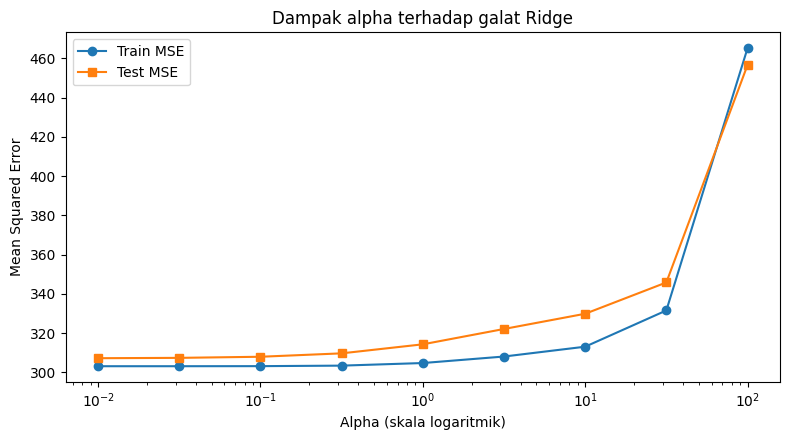

Alpha dengan Test MSE terendah pada grid ini: 0.01


In [9]:
alpha_grid = np.logspace(-2, 2, 9)
train_mse, test_mse = [], []
for alpha in alpha_grid:
    pipe = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    pipe.fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, pipe.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, pipe.predict(X_test)))

plt.figure(figsize=(8, 4.5))
plt.plot(alpha_grid, train_mse, marker="o", label="Train MSE")
plt.plot(alpha_grid, test_mse, marker="s", label="Test MSE")
plt.xscale("log")
plt.xlabel("Alpha (skala logaritmik)")
plt.ylabel("Mean Squared Error")
plt.title("Dampak alpha terhadap galat Ridge")
plt.legend()
plt.tight_layout()
plt.show()

best_idx = int(np.argmin(test_mse))
print(f"Alpha dengan Test MSE terendah pada grid ini: {alpha_grid[best_idx]:.3g}")

## 8. Regresi polinomial untuk pola nonlinier

Regresi polinomial tetap linear terhadap koefisiennya, tetapi fitur masukan diperluas menjadi suku seperti \(x^2\), \(x^3\), dan seterusnya. Dengan demikian, model dapat menggambarkan kurva. Derajat yang tinggi memberi fleksibilitas tambahan, tetapi juga berisiko mengikuti noise.

Untuk menjaga evaluasi tetap adil, pembentukan fitur polinomial dilakukan melalui `Pipeline` dan hanya dipelajari dari data latih.

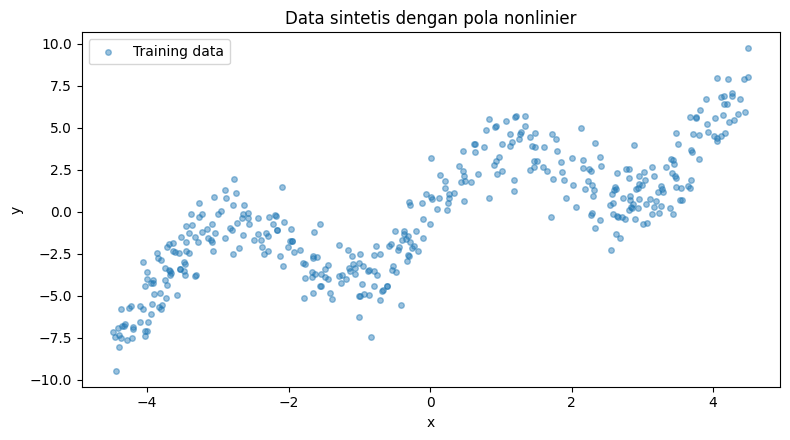

In [10]:
rng_nl = np.random.default_rng(77)
X_curve = rng_nl.uniform(-4.5, 4.5, size=(550, 1))
y_curve = 1.2 * X_curve[:, 0] + 2.8 * np.sin(1.6 * X_curve[:, 0]) + rng_nl.normal(0, 1.2, 550)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_curve, y_curve, test_size=0.25, random_state=77
)

plt.figure(figsize=(8, 4.5))
plt.scatter(Xc_train[:, 0], yc_train, s=16, alpha=0.45, label="Training data")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Data sintetis dengan pola nonlinier")
plt.legend()
plt.tight_layout()
plt.show()

### Membandingkan beberapa derajat polinomial

MSE dan R² berikut dihitung pada set uji. Jangan menyimpulkan bahwa derajat tertinggi pasti terbaik; gunakan hasil pengujian dan bentuk kurva untuk menilai trade-off.

In [11]:
poly_results = []
poly_models = {}
for degree in [1, 2, 3, 5, 7]:
    model = Pipeline([
        ("polynomial", PolynomialFeatures(degree=degree, include_bias=False)),
        ("scale", StandardScaler()),
        ("regression", Ridge(alpha=0.1)),
    ])
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    poly_models[degree] = model
    poly_results.append({
        "Derajat": degree,
        "Test MSE": mean_squared_error(yc_test, pred),
        "Test R²": r2_score(yc_test, pred),
    })
poly_table = pd.DataFrame(poly_results)
display(poly_table.round(4))

,Derajat,Test MSE,Test R²
0,1,3.7116,0.5991
1,2,3.7083,0.5995
2,3,3.7468,0.5953
3,5,2.1310,0.7698
4,7,1.7219,0.8140


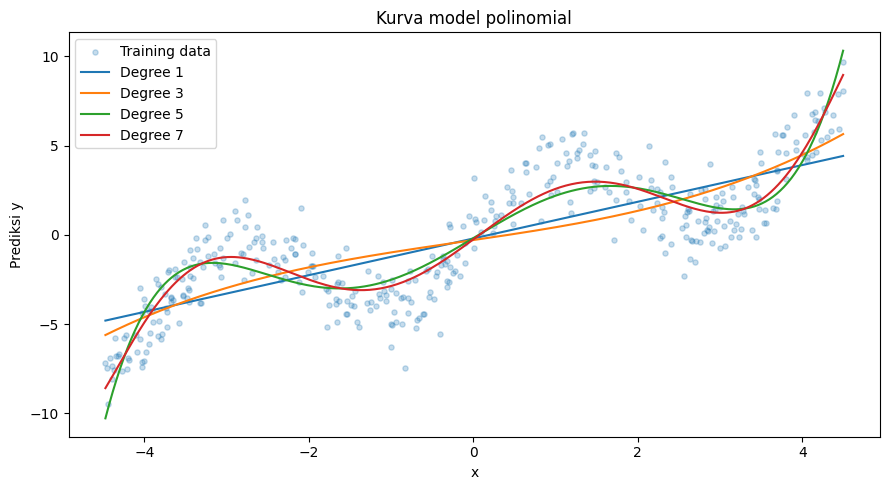

In [12]:
x_grid = np.linspace(X_curve.min(), X_curve.max(), 400).reshape(-1, 1)
plt.figure(figsize=(9, 5))
plt.scatter(Xc_train[:, 0], yc_train, s=14, alpha=0.25, label="Training data")
for degree in [1, 3, 5, 7]:
    plt.plot(x_grid[:, 0], poly_models[degree].predict(x_grid), label=f"Degree {degree}")
plt.xlabel("x")
plt.ylabel("Prediksi y")
plt.title("Kurva model polinomial")
plt.legend()
plt.tight_layout()
plt.show()

## 9. Spline regression

Spline membagi rentang fitur menjadi beberapa bagian dan membangun basis polinomial lokal dengan transisi yang halus di sekitar *knots*. Dibandingkan satu polinomial global berderajat tinggi, spline dapat menyesuaikan bentuk lokal tanpa harus memakai satu kurva yang sangat kompleks untuk seluruh rentang.

Jumlah `n_knots` mengendalikan kelenturan: lebih banyak knot memberi model ruang untuk menangkap pola yang lebih rinci, tetapi juga dapat meningkatkan risiko overfitting.

In [13]:
spline_results = []
spline_models = {}
for knots in [3, 5, 8]:
    model = Pipeline([
        ("spline", SplineTransformer(n_knots=knots, degree=3, include_bias=False)),
        ("scale", StandardScaler()),
        ("regression", Ridge(alpha=1.0)),
    ])
    model.fit(Xc_train, yc_train)
    pred = model.predict(Xc_test)
    spline_models[knots] = model
    spline_results.append({
        "Jumlah knots": knots,
        "Test MSE": mean_squared_error(yc_test, pred),
        "Test R²": r2_score(yc_test, pred),
    })
display(pd.DataFrame(spline_results).round(4))

,Jumlah knots,Test MSE,Test R²
0,3,3.8451,0.5847
1,5,2.6294,0.7160
2,8,1.4270,0.8459


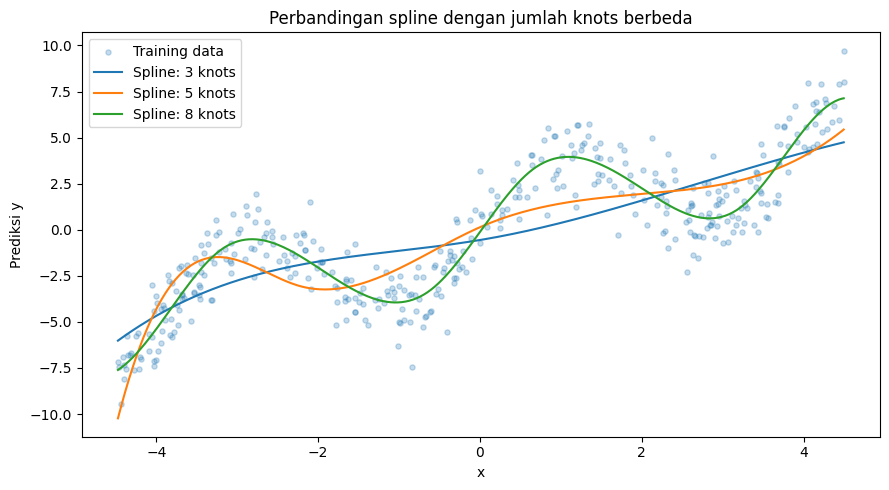

In [14]:
plt.figure(figsize=(9, 5))
plt.scatter(Xc_train[:, 0], yc_train, s=14, alpha=0.25, label="Training data")
for knots in [3, 5, 8]:
    plt.plot(x_grid[:, 0], spline_models[knots].predict(x_grid), label=f"Spline: {knots} knots")
plt.xlabel("x")
plt.ylabel("Prediksi y")
plt.title("Perbandingan spline dengan jumlah knots berbeda")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Kesimpulan Chapter 5

- `LinearRegression` menjadi baseline yang sederhana dan mudah ditafsirkan.
- Ridge mengecilkan koefisien melalui penalti L2, sementara Lasso dapat menghasilkan koefisien tepat nol melalui penalti L1.
- ElasticNet menggabungkan kedua jenis penalti; `alpha` dan `l1_ratio` mengatur perilakunya.
- Pemilihan hyperparameter sebaiknya dilakukan dengan cross-validation. Preprocessing dipasang di dalam pipeline untuk mencegah kebocoran data.
- Polynomial features dan spline dapat memodelkan hubungan nonlinier, tetapi fleksibilitas berlebihan dapat menurunkan kemampuan generalisasi.
- Tidak ada satu metode yang selalu paling baik. Periksa metrik validasi/uji dan pastikan metode sesuai dengan struktur data.

### Latihan mandiri

1. Ubah daftar `candidate_alphas` pada bagian GridSearchCV dan catat perubahan parameter terbaik.
2. Bandingkan hasil Lasso saat `alpha` lebih kecil dan lebih besar.
3. Tambah atau kurangi derajat polinomial dan jumlah knots; bandingkan Test MSE.
4. Jelaskan mengapa scaler dan transformer perlu dipelajari dari data latih saja.

### Referensi

Sukup, John. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Chapter 5: “Linear Models and Regularization”.

Referensi kode resmi penerbit: [PacktPublishing/scikit-learn-Cookbook-Third-Edition](https://github.com/PacktPublishing/scikit-learn-Cookbook-Third-Edition).